### Importing the Dataset

## Part A — Set up

In [13]:
import sys
import platform
import tensorflow as tf

print("Python:     ", sys.version.split()[0])           # expect 3.11.x
print("Interpreter:", sys.executable)                    # should contain envs/cifar10
print("Machine:    ", platform.machine())                # expect arm64 on Apple Silicon
print("TensorFlow: ", tf.__version__)
print("GPUs:       ", tf.config.list_physical_devices("GPU"))  # non-empty only if tensorflow-metal works

Python:      3.11.18
Interpreter: /opt/anaconda3/envs/cifar10/bin/python
Machine:     arm64
TensorFlow:  2.21.0
GPUs:        []


In [14]:
## Import and Random Seed

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

FIG_DIR = Path("../reports/figures")          # notebooks/ is one level below the repo root
FIG_DIR.mkdir(parents=True, exist_ok=True)    # create it if it doesn't exist yet

### Loading the Dataset & Setting the seed

In [18]:
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Load the dataset
print("type:   ", type(x_train))
print("x_train:", x_train.shape, x_train.dtype, "| ndim =", x_train.ndim, "| size =", x_train.size)
print("y_train:", y_train.shape, y_train.dtype)
print("x_test: ", x_test.shape, x_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)
print("pixel range:", x_train.min(), "to", x_train.max())
print("numbers per image:", 32 * 32 * 3)
print("first 10 labels:", y_train[:10].ravel())


type:    <class 'numpy.ndarray'>
x_train: (50000, 32, 32, 3) uint8 | ndim = 4 | size = 153600000
y_train: (50000, 1) uint8
x_test:  (10000, 32, 32, 3) uint8
y_test:  (10000, 1) uint8
pixel range: 0 to 255
numbers per image: 3072
first 10 labels: [6 9 9 4 1 1 2 7 8 3]


channels-first shape: (3, 32, 32)
imshow error: Invalid shape (3, 32, 32) for image data


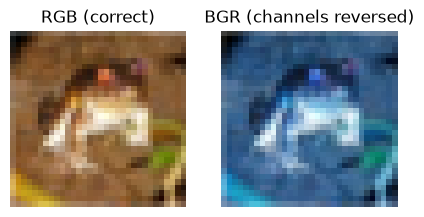

In [19]:
img = x_train[0]

# Experiment 1: channels-first image -> Matplotlib can't display it
img_chw = img.transpose(2, 0, 1)          # (32, 32, 3) -> (3, 32, 32)
print("channels-first shape:", img_chw.shape)
try:
    plt.imshow(img_chw)
except TypeError as e:
    print("imshow error:", e)
plt.close()

# Experiment 2: reversed channel order (RGB -> BGR): same shapes, wrong colours
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
axes[0].imshow(img);            axes[0].set_title("RGB (correct)")
axes[1].imshow(img[..., ::-1]); axes[1].set_title("BGR (channels reversed)")
for ax in axes:
    ax.axis("off")
plt.show()

In [20]:
print(x_train[0].shape)           # (32, 32, 3)     one image
print(x_train[:8].shape)          # (8, 32, 32, 3)  a batch of 8
print(x_train[0:1].shape)         # (1, 32, 32, 3)  a batch of ONE: models always expect this batch axis
print(x_train[0, 5, 10])          # [R G B] values of one pixel, shape (3,)
print(x_train[0, :, :, 0].shape)  # (32, 32)        red channel of the first image
print(y_train[0], "->", y_train[0, 0])  # array([6]) vs the plain integer 6

(32, 32, 3)
(8, 32, 32, 3)
(1, 32, 32, 3)
[123  81  39]
(32, 32)
[6] -> 6


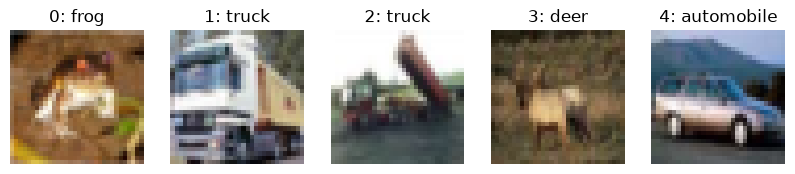

In [21]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for ax, i in zip(axes, [0, 1, 2, 3, 4]):
    ax.imshow(x_train[i])
    ax.set_title(f"{i}: {CLASS_NAMES[y_train[i, 0]]}")
    ax.axis("off")
plt.show()

In [22]:
assert x_train.shape == (50000, 32, 32, 3) and x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1) and y_test.shape == (10000, 1)
assert x_train.dtype == np.uint8
assert x_train.min() == 0 and x_train.max() == 255
assert set(np.unique(y_train)) == set(range(10))
print("All sanity checks passed.")

All sanity checks passed.


In [23]:
distribution = pd.DataFrame({
    "train": np.bincount(y_train.ravel(), minlength=10),
    "test":  np.bincount(y_test.ravel(), minlength=10),
}, index=CLASS_NAMES)
distribution

,train,test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


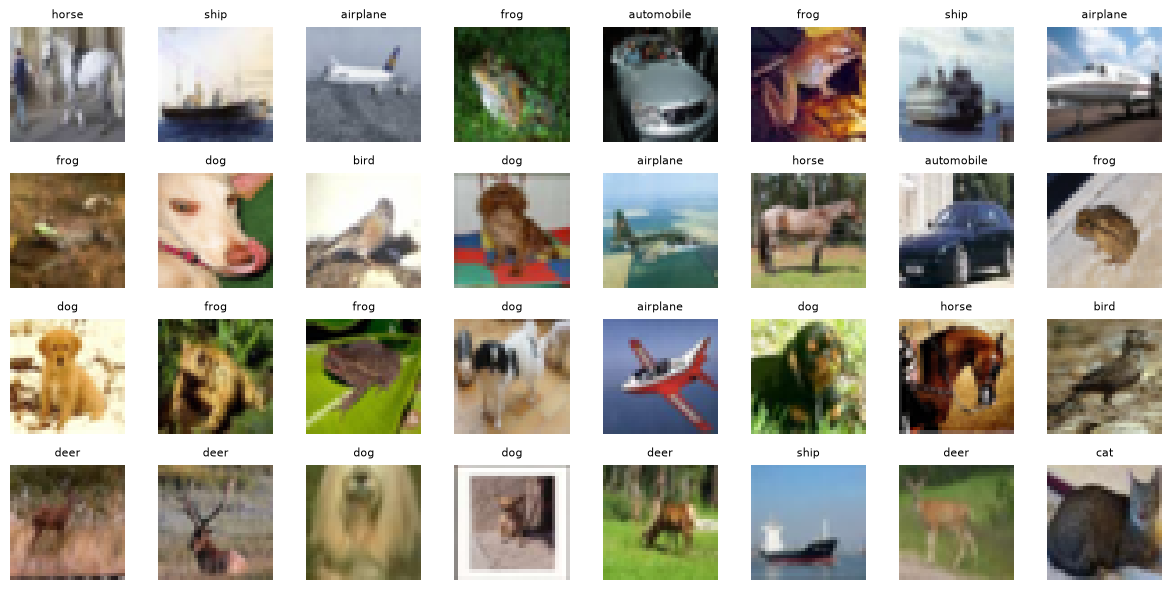

In [24]:
idx = np.random.choice(len(x_train), 32, replace=False)
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for ax, i in zip(axes.flat, idx):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i, 0]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "samples.png", dpi=150)   # save BEFORE show
plt.show()

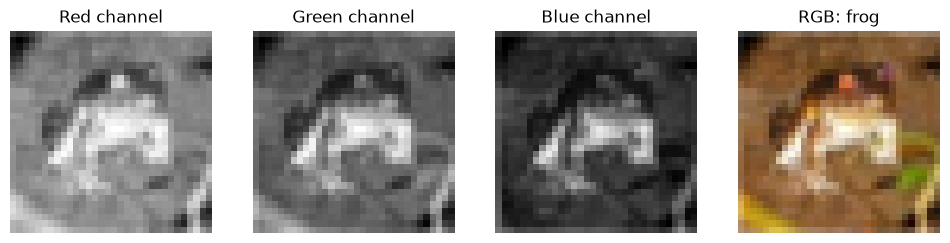

In [25]:
img = x_train[0]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for c, name in enumerate(["Red", "Green", "Blue"]):
    axes[c].imshow(img[:, :, c], cmap="gray", vmin=0, vmax=255)
    axes[c].set_title(f"{name} channel")
axes[3].imshow(img)
axes[3].set_title(f"RGB: {CLASS_NAMES[y_train[0, 0]]}")
for ax in axes:
    ax.axis("off")
plt.show()

In [26]:
mean = x_train.mean(axis=(0, 1, 2))
std = x_train.std(axis=(0, 1, 2))
pd.DataFrame({"mean": mean, "std": std}, index=["R", "G", "B"]).round(2)

,mean,std
R,125.31,62.99
G,122.95,62.09
B,113.87,66.70


In [27]:
x_train_f = x_train.astype("float32") / 255.0
x_test_f = x_test.astype("float32") / 255.0
print(x_train_f.dtype, x_train_f.min(), x_train_f.max())
print(f"memory: {x_train.nbytes / 1e6:.0f} MB as uint8 -> {x_train_f.nbytes / 1e6:.0f} MB as float32")

float32 0.0 1.0
memory: 154 MB as uint8 -> 614 MB as float32


In [28]:
print("bug demo:", (y_train[:5].ravel() == y_train[:5]).shape)   # (5, 5)! not (5,)

y_train_flat = y_train.ravel()
y_test_flat = y_test.ravel()
print("flattened:", y_train_flat.shape, y_test_flat.shape)

# The same labels in one-hot form, for comparison
print("one-hot:\n", tf.keras.utils.to_categorical(y_train_flat[:3], num_classes=10))

bug demo: (5, 5)
flattened: (50000,) (10000,)
one-hot:
 [[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [29]:
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_f, y_train_flat, test_size=5000, stratify=y_train_flat, random_state=42
)
print("train:", x_tr.shape, "| val:", x_val.shape, "| test:", x_test_f.shape)
print("val per class:", np.bincount(y_val))

train: (45000, 32, 32, 3) | val: (5000, 32, 32, 3) | test: (10000, 32, 32, 3)
val per class: [500 500 500 500 500 500 500 500 500 500]
